# Systemy AI – Laboratorium 1
## Python, NumPy i pierwsze metryki klasyfikacji

**Cel:** przypomnienie Pythona w kontekście pracy z wynikami modeli, samodzielna implementacja metryk klasyfikacji binarnej i pierwszy mały eksperyment z hipotezą.

**Zasady**
- Zapisz kopię notatnika na swoim Dysku: *Plik → Zapisz kopię na Dysku*, nazwa `Lab1_AI_Nazwisko.ipynb`.
- Rozwiązania wpisuj w komórkach `# Twoje rozwiązanie`, odpowiedzi opisowe w komórkach *Twoja odpowiedź*.
- Komórki oznaczone `# TEST` sprawdzają rozwiązanie. Nie zmieniaj ich; jeśli zgłaszają błąd, popraw kod powyżej.
- Przed oddaniem: *Środowisko wykonawcze → Uruchom ponownie i uruchom wszystko*. Notatnik musi wykonać się od góry do dołu bez błędów.



**Materiały pomocnicze**
- Python: https://www.w3schools.com/python/ oraz https://www.kaggle.com/learn/python
- NumPy: https://numpy.org/doc/stable/user/quickstart.html
- Metryki w scikit-learn: https://scikit-learn.org/stable/modules/model_evaluation.html

---
## Część A. Rozgrzewka

### Zadanie A1. Pierwsze komórki
1. Wypisz instrukcją `print` tekst `Hello, Artificial Intelligence!`.

In [1]:
# Twoje rozwiązanie
print("Hello, Artificial Intelligence!")

Hello, Artificial Intelligence!


*Twoja odpowiedź:* Hello, Artificial Intelligence!

### Zadanie A2. Zmienne i typy
Zadeklaruj zmienne `model`, `version`, `accuracy`, `deployed` o wartościach `"NeuralNet"`, `2`, `0.94`, `True`.

1. Wypisz typ każdej zmiennej (`type()`).
2. Zbuduj i wypisz zdanie `Model NeuralNet (v2) osiąga dokładność 0.94.` na dwa sposoby: przez konkatenację (`+`, zmienna `s1`) oraz jako f-string (zmienna `s2`).


In [36]:
# Twoje rozwiązanie

model = "NeuralNet"
version = 2
accuracy = 0.94
deployed = True

print(type(model))
print(type(version))
print(type(accuracy))
print(type(deployed))

s1 = "Model " + model + " (v" + str(version) + ") "+ "osiąga dokładność " + str(accuracy) + "."
print(s1)
s2 = f"Model {model} (v{version}) osiąga dokładność {accuracy}."
print(s2)

<class 'str'>
<class 'int'>
<class 'float'>
<class 'bool'>
Model NeuralNet (v2) osiąga dokładność 0.94.
Model NeuralNet (v2) osiąga dokładność 0.94.


In [37]:
# TEST
assert s1 == s2 == "Model NeuralNet (v2) osiąga dokładność 0.94."
print("A2 OK")

A2 OK


### Zadanie A3. Średnia i odchylenie standardowe
Dla listy `acc = [0.78, 0.86, 0.92, 0.81]` oblicz **bez bibliotek**:
- średnią `mean_acc`,
- odchylenie standardowe populacji `std_acc` (z dzieleniem przez $n$):

$$\sigma = \sqrt{\frac{1}{n}\sum_{i=1}^{n}(x_i-\bar{x})^2}$$

W komórce tekstowej zinterpretuj wynik: co mówi odchylenie o tych czterech modelach? Jak zmieni się wartość, jeśli podzielisz przez $n-1$, i kiedy stosuje się ten wariant?

In [21]:
# Twoje rozwiązanie
acc = [0.78, 0.86, 0.92, 0.81]

n=len(acc)

mean_acc = sum(acc)/n
variance = sum((x - mean_acc) ** 2 for x in acc) / n
std_acc = variance ** 0.5

print("mean_acc =", mean_acc)
print("std_acc  =", std_acc)

mean_acc = 0.8425
std_acc  = 0.05309190145398825


In [14]:
# TEST
assert abs(mean_acc - 0.8425) < 1e-9
assert abs(std_acc - 0.05309) < 1e-4, "Sprawdź, czy dzielisz przez n, a nie n-1"
print("A3 OK")

A3 OK


*Twoja odpowiedź:*
Odchylenie 0,053 oznacza, że wyniki czterech modeli są dość blisko średniej 0,8425. Po podzieleniu przez n−1 zamiast n odchylenie wzrośnie do 0,061. Dzielimy przez n−1, gdy badane modele są tylko próbką większej grupy.

### Zadanie A4. Tekst i słownik częstości
Dla tekstu

`text = "AI systems learn from data. AI systems make predictions from data"`

1. Usuń interpunkcję, zamień litery na małe i podziel tekst na słowa.
2. Zbuduj słownik `counts` w postaci `{słowo: liczba_wystąpień}`.
3. Zapisz w liście `most_common` **wszystkie** słowa o największej liczbie wystąpień (uwaga na remisy) i wypisz ją.

In [22]:
# Twoje rozwiązanie
text = "AI systems learn from data. AI systems make predictions from data"

punctuation = ".,;:!?\"'()-"
clean = text.lower()
for ch in punctuation:
    clean = clean.replace(ch, "")
words = clean.split()
print(words)

counts = {}
for w in words:
    counts[w] = counts.get(w, 0) + 1
print(counts)

max_count = max(counts.values())
most_common = [w for w, c in counts.items() if c == max_count]
print(most_common)


['ai', 'systems', 'learn', 'from', 'data', 'ai', 'systems', 'make', 'predictions', 'from', 'data']
{'ai': 2, 'systems': 2, 'learn': 1, 'from': 2, 'data': 2, 'make': 1, 'predictions': 1}
['ai', 'systems', 'from', 'data']


In [23]:
# TEST
assert counts["data"] == 2 and counts["learn"] == 1
assert sorted(most_common) == ["ai", "data", "from", "systems"]
print("A4 OK")

A4 OK


### Zadanie A5. Funkcja z walidacją
Napisz funkcję `performance_label(score)`, która zamienia wynik modelu `score` ∈ [0, 1] na etykietę:

| Warunek | Etykieta |
|---|---|
| `score < 0.75` | `"weak"` |
| `0.75 ≤ score ≤ 0.90` | `"average"` |
| `score > 0.90` | `"strong"` |

Wymagania:
- progi 0.75 i 0.90 należą do `"average"`; funkcja nie zaokrągla wejścia,
- dla wartości nieliczbowej (np. `"0.8"`, `None`) funkcja zgłasza `TypeError`,
- dla liczby spoza [0, 1] funkcja zgłasza `ValueError`.

Następnie dla listy `scores = [0.72, 0.81, 0.93, 0.88]` wypisz każdy wynik z etykietą i policz średnią `mean_ok` tylko z wyników, które **nie** są `"weak"`.

In [24]:
# Twoje rozwiązanie
def performance_label(score):
    if isinstance(score, bool) or not isinstance(score, (int, float)):
        raise TypeError(f"score musi być liczbą, otrzymano: {type(score).__name__}")
    if not (0 <= score <= 1):
        raise ValueError(f"score musi należeć do [0, 1], otrzymano: {score}")

    if score < 0.75:
        return "weak"
    elif score <= 0.90:
        return "average"
    else:
        return "strong"


scores = [0.72, 0.81, 0.93, 0.88]

labeled = []
for s in scores:
    label = performance_label(s)
    labeled.append((s, label))
    print(f"{s} -> {label}")

ok_scores = [s for s, label in labeled if label != "weak"]
mean_ok = sum(ok_scores) / len(ok_scores)
print("mean_ok =", mean_ok)

0.72 -> weak
0.81 -> average
0.93 -> strong
0.88 -> average
mean_ok = 0.8733333333333334


In [25]:
# TEST
assert [performance_label(s) for s in (0.74, 0.75, 0.90, 0.95)] == ["weak", "average", "average", "strong"]
assert performance_label(0) == "weak" and performance_label(1) == "strong"

for bad, exc in [(1.2, ValueError), (-0.1, ValueError), ("0.8", TypeError), (None, TypeError)]:
    try:
        performance_label(bad)
    except exc:
        pass
    else:
        raise AssertionError(f"Dla {bad!r} oczekiwano wyjątku {exc.__name__}")

assert abs(mean_ok - 0.87333) < 1e-4
print("A5 OK")

A5 OK


---
## Część B. Struktury danych i wyniki modeli

### Zadanie B1. Słownik wyników i ranking
1. Utwórz słownik `results`: `"SVM"` → 0.81, `"DecisionTree"` → 0.74, `"NeuralNet"` → 0.92.
2. Dodaj do niego `"Transformer"` → 0.95.
3. Oblicz średnią dokładność `mean_results` i utwórz listę `above_mean` z nazwami modeli o dokładności powyżej średniej.
4. Napisz funkcję `print_ranking(results)`, która drukuje ranking malejąco w formacie

```
1. Transformer – 0.95
2. NeuralNet – 0.92
...
Najlepszy model: Transformer – rekomendowany do wdrożenia
```

i **zwraca** nazwę najlepszego modelu. Funkcja nie może modyfikować przekazanego słownika.

In [31]:
# Twoje rozwiązanie

results = {"SVM": 0.81, "DecisionTree": 0.74, "NeuralNet": 0.92}

results["Transformer"] = 0.95

mean_results = sum(results.values()) / len(results)
above_mean = [name for name, acc in results.items() if acc > mean_results]
print("mean_results =", mean_results)
print("above_mean   =", above_mean)


def print_ranking(results):
    ranking = sorted(results.items(), key=lambda item: item[1], reverse=True)

    for place, (name, acc) in enumerate(ranking, start=1):
        print(f"{place}. {name} – {acc:.2f}")

    best = ranking[0][0]
    print(f"Najlepszy model: {best} – rekomendowany do wdrożenia")
    return best


best_model = print_ranking(results)
print("Zwrócono:", best_model)
print("results po wywołaniu:", results)

mean_results = 0.855
above_mean   = ['NeuralNet', 'Transformer']
1. Transformer – 0.95
2. NeuralNet – 0.92
3. SVM – 0.81
4. DecisionTree – 0.74
Najlepszy model: Transformer – rekomendowany do wdrożenia
Zwrócono: Transformer
results po wywołaniu: {'SVM': 0.81, 'DecisionTree': 0.74, 'NeuralNet': 0.92, 'Transformer': 0.95}


In [32]:
# TEST
assert abs(mean_results - 0.855) < 1e-9
assert sorted(above_mean) == ["NeuralNet", "Transformer"]
assert print_ranking({"A": 0.5, "B": 0.7}) == "B"
assert list(results) == ["SVM", "DecisionTree", "NeuralNet", "Transformer"], "Funkcja zmieniła słownik"
print("B1 OK")

1. B – 0.70
2. A – 0.50
Najlepszy model: B – rekomendowany do wdrożenia
B1 OK


### Zadanie B2. Filtrowanie błędnych wyników
Dane z eksperymentów bywają zanieczyszczone. Dla listy

`raw = [0.83, 0.92, 1.05, -0.12, 0.78, None]`

napisz funkcję `clean_scores(raw)`, która zwraca parę `(valid, n_invalid)`:
- `valid` – lista poprawnych wyników (liczby z zakresu [0, 1]),
- `n_invalid` – liczba odrzuconych wartości.

Wypisz komunikat dokładnie w formacie:

`Poprawne: 3 | Błędne: 3 | Średnia (poprawnych): 0.84`

*Dla dociekliwych:* co Twoja funkcja zrobi z wartościami `"0.9"` i `True`? Czy tak powinno być?

In [28]:
# Twoje rozwiązanie

def clean_scores(raw):
    valid = []
    n_invalid = 0
    for x in raw:
        is_number = isinstance(x, (int, float)) and not isinstance(x, bool)
        if is_number and 0 <= x <= 1:
            valid.append(x)
        else:
            n_invalid += 1
    return valid, n_invalid


raw = [0.83, 0.92, 1.05, -0.12, 0.78, None]

valid, n_invalid = clean_scores(raw)
mean_valid = sum(valid) / len(valid)

print(f"Poprawne: {len(valid)} | Błędne: {n_invalid} | Średnia (poprawnych): {mean_valid:.2f}")

Poprawne: 3 | Błędne: 3 | Średnia (poprawnych): 0.84


In [29]:
# TEST
assert clean_scores([0.83, 0.92, 1.05, -0.12, 0.78, None]) == ([0.83, 0.92, 0.78], 3)
assert clean_scores([0, 1, "0.9"]) == ([0, 1], 1)
print("B2 OK")

B2 OK


### Zadanie B3. Struktura zagnieżdżona
Dla struktury `model_info` (komórka niżej) napisz funkcję `summarize_model(info)`, która:
1. wypisuje nazwę modelu,
2. oblicza i wypisuje średnią ze **wszystkich** metryk w `info["metrics"]` (nie zakładaj, że są dokładnie trzy),
3. wypisuje `Model gotowy do wdrożenia`, jeśli średnia ≥ 0.9, w przeciwnym razie `Model wymaga poprawy`,
4. zapisuje średnią pod kluczem `info["mean_score"]` i zwraca cały słownik.

Wywołaj funkcję: `model_info = summarize_model(model_info)`.

In [ ]:
model_info = {
    "name": "NeuralNet",
    "version": "1.2",
    "metrics": {"accuracy": 0.91, "precision": 0.88, "recall": 0.85},
    "status": "trained",
}

In [39]:
# Twoje rozwiązanie
model_info = {
    "name": "NeuralNet",
    "version": "1.2",
    "metrics": {"accuracy": 0.91, "precision": 0.88, "recall": 0.85},
    "status": "trained",
}

def summarize_model(info):
    metrics = info["metrics"]
    values = list(metrics.values()) if isinstance(metrics, dict) else list(metrics)

    if not values:
        raise ValueError("info['metrics'] jest puste – nie można policzyć średniej")

    mean_score = sum(values) / len(values)

    print("Model:", info["name"])
    print(f"Średnia metryk: {mean_score:.4f}")
    if mean_score >= 0.9:
        print("Model gotowy do wdrożenia")
    else:
        print("Model wymaga poprawy")

    info["mean_score"] = mean_score
    return info


model_info = summarize_model(model_info)
print(model_info)

Model: NeuralNet
Średnia metryk: 0.8800
Model wymaga poprawy
{'name': 'NeuralNet', 'version': '1.2', 'metrics': {'accuracy': 0.91, 'precision': 0.88, 'recall': 0.85}, 'status': 'trained', 'mean_score': 0.88}


In [40]:
# TEST
assert abs(model_info["mean_score"] - 0.88) < 1e-9
assert abs(summarize_model({"name": "X", "metrics": {"accuracy": 0.95, "f1": 0.93}})["mean_score"] - 0.94) < 1e-9
print("B3 OK")

Model: X
Średnia metryk: 0.9400
Model gotowy do wdrożenia
B3 OK


---
## Część C. Metryki klasyfikacji binarnej

Przypomnienie (klasa pozytywna = 1):

| | predykcja 1 | predykcja 0 |
|---|---|---|
| **prawda 1** | TP | FN |
| **prawda 0** | FP | TN |

$$\text{accuracy}=\frac{TP+TN}{TP+TN+FP+FN}\qquad \text{precision}=\frac{TP}{TP+FP}\qquad \text{recall}=\frac{TP}{TP+FN}\qquad F_1=\frac{2\cdot\text{precision}\cdot\text{recall}}{\text{precision}+\text{recall}}$$

In [ ]:
y_true = [1, 0, 1, 1, 0, 0, 1, 0, 1, 0]
y_pred = [1, 0, 1, 0, 0, 1, 1, 0, 0, 0]

### Zadanie C1. Ręcznie, w czystym Pythonie
Używając pętli (bez bibliotek) policz i zapisz w zmiennych `TP`, `FP`, `FN`, `TN`, a następnie `precision`, `recall` i `f1`. Wypisz raport:

`TP=.. FP=.. FN=.. TN=.. / precision=.. recall=.. F1=..`

In [41]:
# Twoje rozwiązanie
y_true = [1, 0, 1, 1, 0, 0, 1, 0, 1, 0]
y_pred = [1, 0, 1, 0, 0, 1, 1, 0, 0, 0]

TP = FP = FN = TN = 0

for t, p in zip(y_true, y_pred):
    if t == 1 and p == 1:
        TP += 1
    elif t == 0 and p == 1:
        FP += 1
    elif t == 1 and p == 0:
        FN += 1
    else:  # t == 0 and p == 0
        TN += 1

precision = TP / (TP + FP) if (TP + FP) > 0 else 0.0
recall = TP / (TP + FN) if (TP + FN) > 0 else 0.0
f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0.0

print(f"TP={TP} FP={FP} FN={FN} TN={TN} / "
      f"precision={precision:.3f} recall={recall:.3f} F1={f1:.3f}")

TP=3 FP=1 FN=2 TN=4 / precision=0.750 recall=0.600 F1=0.667


In [42]:
# TEST
assert (TP, FP, FN, TN) == (3, 1, 2, 4)
assert abs(precision - 0.75) < 1e-9 and abs(recall - 0.6) < 1e-9 and abs(f1 - 2 / 3) < 1e-9
print("C1 OK")

C1 OK


### Zadanie C2. To samo w NumPy
Napisz funkcję `binary_metrics(y_true, y_pred)`, która **bez pętli** (maski logiczne i `sum`) zwraca słownik z kluczami

`"TP", "FP", "FN", "TN", "accuracy", "precision", "recall", "f1"`.

Jeśli mianownik którejś metryki jest równy 0 (np. model ani razu nie przewidział klasy 1), przyjmij dla niej wartość `0.0`. Funkcja ma działać zarówno dla list, jak i tablic NumPy.

In [43]:
import numpy as np

# Twoje rozwiązanie

def binary_metrics(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    if y_true.shape != y_pred.shape:
        raise ValueError("y_true i y_pred muszą mieć ten sam kształt")

    t = (y_true == 1)
    p = (y_pred == 1)

    TP = int(np.sum(t & p))
    FP = int(np.sum(~t & p))
    FN = int(np.sum(t & ~p))
    TN = int(np.sum(~t & ~p))

    def safe_div(num, den):
        return num / den if den > 0 else 0.0

    accuracy = safe_div(TP + TN, TP + TN + FP + FN)
    precision = safe_div(TP, TP + FP)
    recall = safe_div(TP, TP + FN)
    f1 = safe_div(2 * precision * recall, precision + recall)

    return {
        "TP": TP, "FP": FP, "FN": FN, "TN": TN,
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1,
    }


y_true = [1, 0, 1, 1, 0, 0, 1, 0, 1, 0]
y_pred = [1, 0, 1, 0, 0, 1, 1, 0, 0, 0]

print(binary_metrics(y_true, y_pred))
print(binary_metrics(np.array(y_true), np.array(y_pred)))

print(binary_metrics([1, 0, 1, 0], [0, 0, 0, 0]))

{'TP': 3, 'FP': 1, 'FN': 2, 'TN': 4, 'accuracy': 0.7, 'precision': 0.75, 'recall': 0.6, 'f1': 0.6666666666666665}
{'TP': 3, 'FP': 1, 'FN': 2, 'TN': 4, 'accuracy': 0.7, 'precision': 0.75, 'recall': 0.6, 'f1': 0.6666666666666665}
{'TP': 0, 'FP': 0, 'FN': 2, 'TN': 2, 'accuracy': 0.5, 'precision': 0.0, 'recall': 0.0, 'f1': 0.0}


In [44]:
# TEST
m = binary_metrics(y_true, y_pred)
assert (m["TP"], m["FP"], m["FN"], m["TN"]) == (3, 1, 2, 4)
assert abs(m["accuracy"] - 0.7) < 1e-9 and abs(m["f1"] - 2 / 3) < 1e-9

m0 = binary_metrics([1, 0, 0, 0], [0, 0, 0, 0])   # model nigdy nie przewiduje 1
assert m0["precision"] == 0.0 and m0["recall"] == 0.0 and m0["f1"] == 0.0
print("C2 OK")

C2 OK


### Zadanie C3. Porównanie ze scikit-learn
Policz te same wielkości funkcjami `confusion_matrix`, `accuracy_score`, `precision_score`, `recall_score`, `f1_score` z modułu `sklearn.metrics` i sprawdź (`np.isclose`), że zgadzają się z wynikiem `binary_metrics`.

W komentarzu zapisz, w jakim układzie `confusion_matrix` zwraca TP, FP, FN, TN. Sprawdź to w dokumentacji, nie zgaduj.

In [47]:
# Twoje rozwiązanie

import numpy as np
from sklearn.metrics import (confusion_matrix, accuracy_score,
                             precision_score, recall_score, f1_score)

m = binary_metrics(y_true, y_pred)

tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()

sk = {
    "TP": tp, "FP": fp, "FN": fn, "TN": tn,
    "accuracy":  accuracy_score(y_true, y_pred),
    "precision": precision_score(y_true, y_pred, zero_division=0),
    "recall":    recall_score(y_true, y_pred, zero_division=0),
    "f1":        f1_score(y_true, y_pred, zero_division=0),
}

for key in ["TP", "FP", "FN", "TN", "accuracy", "precision", "recall", "f1"]:
    ok = np.isclose(m[key], sk[key])
    print(f"{key:9s} moje={m[key]:.4f}  sklearn={sk[key]:.4f}  zgodne={ok}")
    assert ok, f"Niezgodność dla {key}"

print("C3 OK")

TP        moje=3.0000  sklearn=3.0000  zgodne=True
FP        moje=1.0000  sklearn=1.0000  zgodne=True
FN        moje=2.0000  sklearn=2.0000  zgodne=True
TN        moje=4.0000  sklearn=4.0000  zgodne=True
accuracy  moje=0.7000  sklearn=0.7000  zgodne=True
precision moje=0.7500  sklearn=0.7500  zgodne=True
recall    moje=0.6000  sklearn=0.6000  zgodne=True
f1        moje=0.6667  sklearn=0.6667  zgodne=True
C3 OK


---
## Część D. Mini-eksperyment: kiedy accuracy wprowadza w błąd

Rozważ dwa „modele” wykrywające rzadkie zjawisko (np. chorobę, awarię, oszustwo):

- **zawsze-zero** – niezależnie od wejścia odpowiada 0,
- **zaszumiony** – zna prawdziwą odpowiedź, ale w 10% przypadków (losowo) podaje przeciwną.

Parametr $p$ to udział klasy pozytywnej w danych.

### Zadanie D1. Hipoteza
**Zanim uruchomisz jakikolwiek kod**, zapisz przewidywania dla $p = 0.05$:
- jaką accuracy osiągnie każdy z modeli?
- który model będzie miał wyższą accuracy?
- jaką precision będzie miał model zaszumiony: bliżej 0.9, 0.5 czy 0.3?

*Twoja odpowiedź:*
Model zawsze-zero: accuracy około 0,95, bo 95% danych to klasa negatywna.
Model zaszumiony: accuracy około 0,90, ponieważ myli się w 10% przypadków.
Wyższa accuracy: model zawsze-zero.
Precision modelu zaszumionego: bliżej 0,3, ponieważ przy rzadkiej klasie pozytywnej pojawia się dużo fałszywych alarmów.

Funkcja poniżej generuje dane. Jest gotowa, przeczytaj ją i upewnij się, że rozumiesz każdą linię.

In [ ]:
import numpy as np

def make_data(p, n=10_000, error_rate=0.10, seed=42):
    """Zwraca (y_true, y_zero, y_noisy) dla udziału klasy pozytywnej p."""
    rng = np.random.default_rng(seed)
    y_true = (rng.random(n) < p).astype(int)        # 1 z prawdopodobieństwem p
    y_zero = np.zeros(n, dtype=int)                 # model zawsze-zero
    flip = rng.random(n) < error_rate               # które odpowiedzi odwrócić
    y_noisy = np.where(flip, 1 - y_true, y_true)    # model zaszumiony
    return y_true, y_zero, y_noisy

### Zadanie D2. Eksperyment
1. Dla $p = 0.05$ policz funkcją `binary_metrics` metryki obu modeli i porównaj z przewidywaniami z D1.
2. Powtórz obliczenia dla `ps = [0.5, 0.3, 0.1, 0.05, 0.01]`. Wyniki zbierz w tabeli `pandas.DataFrame` o nazwie `df` z kolumnami `p`, `model`, `accuracy`, `precision`, `recall`, `f1` (po jednym wierszu na parę: wartość $p$, model).
3. Narysuj wykres (matplotlib): oś X to $p$ w skali logarytmicznej, na osi Y accuracy obu modeli oraz precision modelu zaszumionego. Podpisz osie i dodaj legendę.

In [52]:
# Twoje rozwiązanie
import pandas as pd

def make_data(p, n=10_000, error_rate=0.10, seed=42):
    rng = np.random.default_rng(seed)
    y_true = (rng.random(n) < p).astype(int)
    y_zero = np.zeros(n, dtype=int)
    flip = rng.random(n) < error_rate
    y_noisy = np.where(flip, 1 - y_true, y_true)
    return y_true, y_zero, y_noisy

y_true, y_zero, y_noisy = make_data(p=0.05)

print("Wyniki dla p = 0.05")
print("zawsze-zero:", binary_metrics(y_true, y_zero))
print("zaszumiony:", binary_metrics(y_true, y_noisy))

ps = [0.5, 0.3, 0.1, 0.05, 0.01]
rows = []

for p in ps:
    y_true, y_zero, y_noisy = make_data(p=p)

    for model, y_pred in [
        ("zawsze-zero", y_zero),
        ("zaszumiony", y_noisy)
    ]:
        metrics = binary_metrics(y_true, y_pred)

        rows.append({
            "p": p,
            "model": model,
            "accuracy": metrics["accuracy"],
            "precision": metrics["precision"],
            "recall": metrics["recall"],
            "f1": metrics["f1"]
        })

df = pd.DataFrame(
    rows,
    columns=["p", "model", "accuracy", "precision", "recall", "f1"]
)

print("\nTabela wyników:")
print(df.round(4).to_string(index=False))


Wyniki dla p = 0.05
zawsze-zero: {'TP': 0, 'FP': 0, 'FN': 508, 'TN': 9492, 'accuracy': 0.9492, 'precision': 0.0, 'recall': 0.0, 'f1': 0.0}
zaszumiony: {'TP': 470, 'FP': 926, 'FN': 38, 'TN': 8566, 'accuracy': 0.9036, 'precision': 0.336676217765043, 'recall': 0.9251968503937008, 'f1': 0.49369747899159666}

Tabela wyników:
   p       model  accuracy  precision  recall     f1
0.50 zawsze-zero    0.4985     0.0000  0.0000 0.0000
0.50  zaszumiony    0.9036     0.9023  0.9059 0.9041
0.30 zawsze-zero    0.6957     0.0000  0.0000 0.0000
0.30  zaszumiony    0.9036     0.8023  0.9067 0.8513
0.10 zawsze-zero    0.9016     0.0000  0.0000 0.0000
0.10  zaszumiony    0.9036     0.5057  0.9075 0.6495
0.05 zawsze-zero    0.9492     0.0000  0.0000 0.0000
0.05  zaszumiony    0.9036     0.3367  0.9252 0.4937
0.01 zawsze-zero    0.9899     0.0000  0.0000 0.0000
0.01  zaszumiony    0.9036     0.0910  0.9505 0.1661


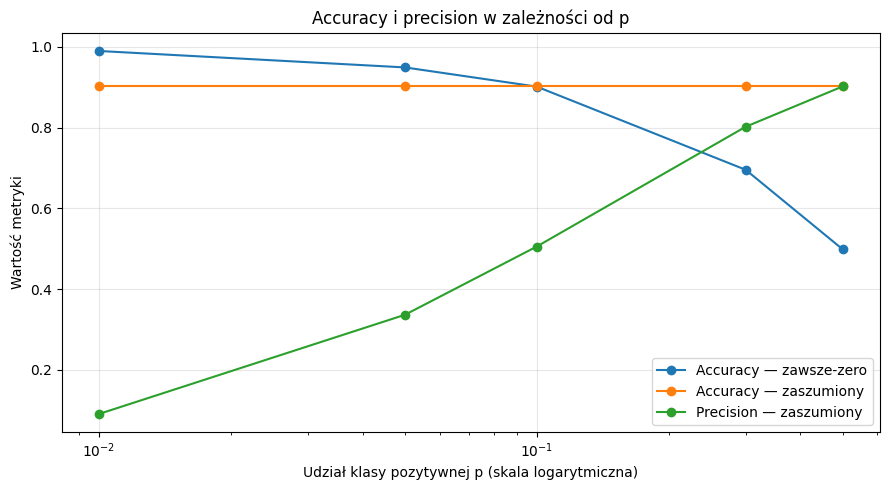

In [54]:
import matplotlib.pyplot as plt

# Twoje rozwiązanie (wykres)

zero = df[df["model"] == "zawsze-zero"].sort_values("p")
noisy = df[df["model"] == "zaszumiony"].sort_values("p")

plt.figure(figsize=(9, 5))

plt.plot(
    zero["p"], zero["accuracy"],
    marker="o", label="Accuracy — zawsze-zero"
)

plt.plot(
    noisy["p"], noisy["accuracy"],
    marker="o", label="Accuracy — zaszumiony"
)

plt.plot(
    noisy["p"], noisy["precision"],
    marker="o", label="Precision — zaszumiony"
)

plt.xscale("log")
plt.xlabel("Udział klasy pozytywnej p (skala logarytmiczna)")
plt.ylabel("Wartość metryki")
plt.title("Accuracy i precision w zależności od p")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [55]:
# TEST
assert set(df.columns) >= {"p", "model", "accuracy", "precision", "recall", "f1"}
assert len(df) == 10
z = df[(df["model"] == "zawsze-zero") & (df["p"] == 0.01)].iloc[0]
assert z["accuracy"] > 0.98 and z["recall"] == 0.0
print("D2 OK")

D2 OK


### Zadanie D3. Wnioski
Odpowiedz krótko (2–3 zdania na pytanie), odwołując się do liczb z tabeli:

1. Czy Twoje przewidywania z D1 się potwierdziły? Co Cię zaskoczyło?
2. Dla $p = 0.01$: który model ma wyższą accuracy, a który jest bardziej użyteczny? Dlaczego?
3. Model zaszumiony myli się zawsze w 10% przypadków. Dlaczego mimo to jego precision spada, gdy $p$ maleje?
4. Projektujesz system wykrywający rzadką chorobę. Którą metrykę zaraportujesz jako główną? Jakie konsekwencje dla pacjentów mają błędy FP, a jakie FN?

*Twoja odpowiedź:*
1. Tak, potwierdziły model zawsze-zero osiągnął accuracy 94,92%, a zaszumiony 90,36%. Zaskoczyło mnie, że model zawsze-zero ma wysoką accuracy, mimo że jego recall wynosi 0%, czyli nie wykrywa żadnego przypadku pozytywnego.

2. Model zawsze-zero ma wyższą accuracy (98,99%) niż zaszumiony (90,36%). Jednak model zaszumiony jest bardziej użyteczny, ponieważ wykrywa 95,05% rzeczywistych przypadków pozytywnych, podczas gdy zawsze-zero nie wykrywa żadnego.

3. Gdy klasa pozytywna staje się rzadsza, rośnie udział fałszywych alarmów wśród wszystkich przewidywanych pozytywów. W tabeli precision spada z 90,23% dla p=0.5
do zaledwie 9,10% dla p=0.01

4. Jako główną metrykę wybrałbym recall, ponieważ niski recall oznacza, że wielu chorych pozostanie niewykrytych. Fałszywie pozytywne wyniki mogą powodować stres i niepotrzebne badania, natomiast fałszywie negatywne mogą opóźnić diagnozę i leczenie, zagrażając zdrowiu pacjentów.

---
## Część E. Zadania dodatkowe (dla chętnych / do domu)

**E1. Pliki.** Zapisz listę wyników (po jednym w linii) do pliku `scores.txt`. Wczytaj plik, oblicz średnią i zapisz do `report.txt` raport w formacie `Wczytano N wyników, średnia: X` (X z dokładnością do 3 miejsc po przecinku).

**E2. Dane od użytkownika.** Pobierz funkcją `input()` wynik modelu `s` i wypisz:
- `Podano niepoprawną wartość!`, gdy tekstu nie da się zamienić na liczbę (`try`/`except`),
- `Wynik poza zakresem 0–1`, gdy `s < 0` lub `s > 1`,
- `Model wymaga poprawy`, gdy `s < 0.7`,
- `Wynik akceptowalny`, gdy `0.7 ≤ s < 0.85`,
- `Wynik doskonały` w pozostałych przypadkach.

**E3. Duplikaty.** Usuń duplikaty z listy `["SVM", "SVM", "NeuralNet", "NeuralNet", "Transformer"]` **z zachowaniem kolejności** pierwszych wystąpień. Dlaczego samo `list(set(...))` tego nie gwarantuje?

**E4. Uogólnienie.** Rozszerz `make_data` o parametr pozwalający ustawić osobno odsetek błędów dla przykładów pozytywnych i negatywnych. Jak zmienia się wykres z D2, gdy model myli się w 10% pozytywnych, ale tylko w 1% negatywnych?

In [ ]:
# Twoje rozwiązanie

import numpy as np
import matplotlib.pyplot as plt

# E1

scores = [0.85, 0.92, 0.67, 0.78, 0.95]

with open("scores.txt", "w", encoding="utf-8") as f:
    for score in scores:
        f.write(f"{score}\n")

with open("scores.txt", "r", encoding="utf-8") as f:
    loaded_scores = [float(line.strip()) for line in f if line.strip()]

n = len(loaded_scores)
average = sum(loaded_scores) / n if n > 0 else 0

report = f"Wczytano {n} wyników, średnia: {average:.3f}"

with open("report.txt", "w", encoding="utf-8") as f:
    f.write(report)

print("E1:", report)



# E2

s = input("\nPodaj wynik modelu (0–1): ")

try:
    s = float(s)

    if s < 0 or s > 1:
        print("Wynik poza zakresem 0–1")
    elif s < 0.7:
        print("Model wymaga poprawy")
    elif s < 0.85:
        print("Wynik akceptowalny")
    else:
        print("Wynik doskonały")

except ValueError:
    print("Podano niepoprawną wartość!")

# E3

models = [
    "SVM", "SVM", "NeuralNet", "NeuralNet", "Transformer"
]

unique_models = list(dict.fromkeys(models))

print("\nE3:", unique_models)

# E4

def make_data(p, n=10_000, error_positive=0.10,
              error_negative=0.01, seed=42):
    rng = np.random.default_rng(seed)

    y_true = (rng.random(n) < p).astype(int)
    y_zero = np.zeros(n, dtype=int)

    error_rates = np.where(
        y_true == 1,
        error_positive,
        error_negative
    )

    flip = rng.random(n) < error_rates
    y_noisy = np.where(flip, 1 - y_true, y_true)

    return y_true, y_zero, y_noisy


def binary_metrics(y_true, y_pred):
    tp = np.sum((y_true == 1) & (y_pred == 1))
    tn = np.sum((y_true == 0) & (y_pred == 0))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == 0))

    accuracy = (tp + tn) / len(y_true)
    precision = tp / (tp + fp) if tp + fp > 0 else 0.0
    recall = tp / (tp + fn) if tp + fn > 0 else 0.0
    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall > 0 else 0.0
    )

    return {
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1
    }


ps = [0.5, 0.3, 0.1, 0.05, 0.01]
rows = []

for p in ps:
    y_true, y_zero, y_noisy = make_data(p=p)

    for model_name, y_pred in [
        ("zawsze-zero", y_zero),
        ("zaszumiony", y_noisy)
    ]:
        metrics = binary_metrics(y_true, y_pred)

        rows.append({
            "p": p,
            "model": model_name,
            "accuracy": metrics["accuracy"],
            "precision": metrics["precision"],
            "recall": metrics["recall"],
            "f1": metrics["f1"]
        })

# Tabela wyników
import pandas as pd

df_e4 = pd.DataFrame(rows)

print("\nE4. Tabela wyników:")
print(df_e4.round(4).to_string(index=False))


# Wykres metryk
zero = df_e4[df_e4["model"] == "zawsze-zero"].sort_values("p")
noisy = df_e4[df_e4["model"] == "zaszumiony"].sort_values("p")

plt.figure(figsize=(9, 5))

plt.plot(
    zero["p"], zero["accuracy"],
    marker="o", label="Accuracy — zawsze-zero"
)
plt.plot(
    noisy["p"], noisy["accuracy"],
    marker="o", label="Accuracy — zaszumiony"
)
plt.plot(
    noisy["p"], noisy["precision"],
    marker="o", label="Precision — zaszumiony"
)

plt.xscale("log")
plt.xlabel("Udział klasy pozytywnej p (skala logarytmiczna)")
plt.ylabel("Wartość metryki")
plt.title("E4: Metryki przy różnych odsetkach błędów")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()